# Clustering
## Load Data

In [1]:

import pandas as pd
from sklearn.preprocessing import StandardScaler

# 1. Load the dataset (fixed the double .parquet typo)
df = pd.read_parquet('../data/network_intrusion_clustering.parquet')

# 2. Drop Label — clustering is unsupervised, Label used only for evaluation
# Notice we are using 'df' here, not 'df_clustering'
X = df.drop(columns=['Label'])
y = df['Label']  # saved for post-hoc interpretation

# 3. Standardize features (zero mean, unit variance)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print(f"Feature matrix shape : {X_scaled.shape}")
print(f"Label series shape   : {y.shape}")
print("All scaled with standart scaler ")

Feature matrix shape : (50420, 25)
Label series shape   : (50420,)
All scaled with standart scaler 


In [2]:
import json

# 1. Load the label mapping JSON file
# (Make sure the path matches your folder structure)
with open('../data/label_mapping.json', 'r') as f:
    label_mapping = json.load(f)

# 2. Reverse the dictionary so numbers are the keys
# JSON saves keys as strings, so we convert the value 'v' to an integer
inverse_mapping = {int(v): k for k, v in label_mapping.items()}

# 3. Create a permanent 'Label_Name' column for easy evaluation later
df['Label_Name'] = df['Label'].map(inverse_mapping)

print("Label mapping loaded!")

Label mapping loaded!


## K-Means

k= 2 | Inertia:    1061440.9 | Silhouette: 0.5135 | Davies-Bouldin: 1.6709
k= 3 | Inertia:     985327.9 | Silhouette: 0.6301 | Davies-Bouldin: 1.2235
k= 4 | Inertia:     896926.3 | Silhouette: 0.4937 | Davies-Bouldin: 1.3371
k= 5 | Inertia:     813464.2 | Silhouette: 0.4205 | Davies-Bouldin: 1.4093
k= 6 | Inertia:     750604.5 | Silhouette: 0.4320 | Davies-Bouldin: 1.2638
k= 7 | Inertia:     687251.9 | Silhouette: 0.4329 | Davies-Bouldin: 1.1453
k= 8 | Inertia:     653142.5 | Silhouette: 0.4562 | Davies-Bouldin: 1.0633
k= 9 | Inertia:     598468.7 | Silhouette: 0.4756 | Davies-Bouldin: 1.0775
k=10 | Inertia:     564408.3 | Silhouette: 0.4640 | Davies-Bouldin: 1.0100


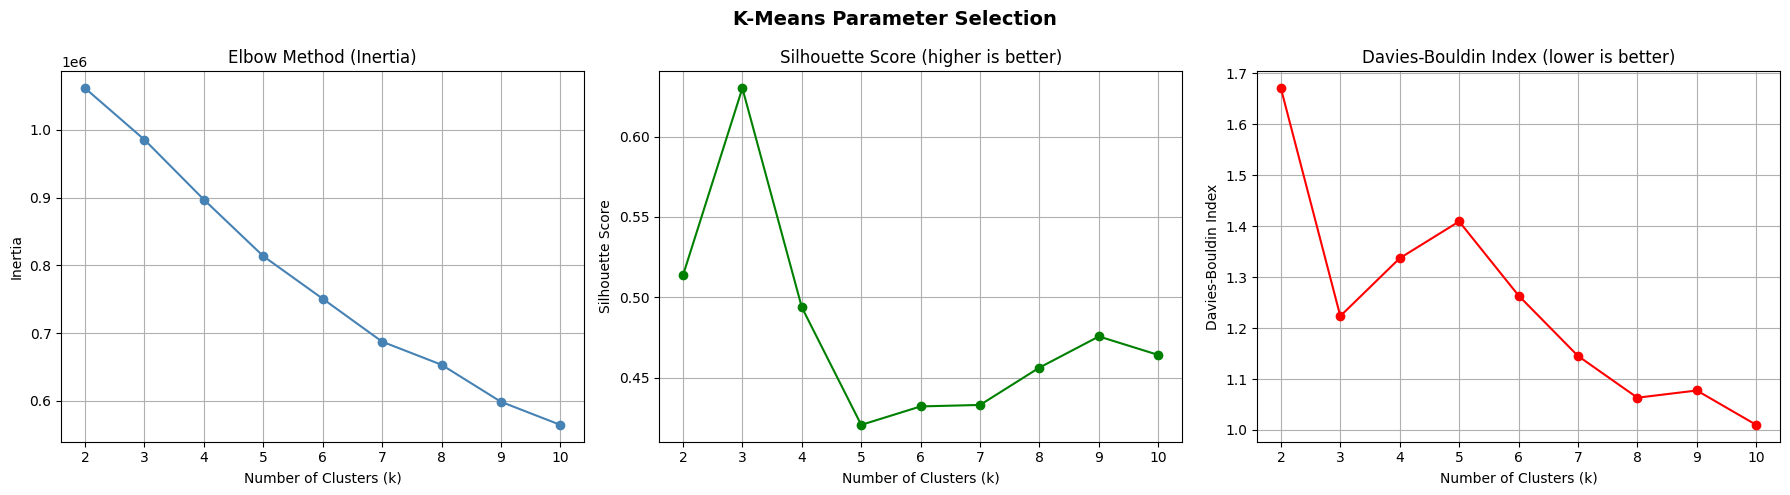


Best k selected: 3
   Silhouette Score : 0.6301
   Davies-Bouldin   : 1.2235

 K-Means complete. Cluster labels saved to df.


In [3]:
# =============================================================
# K-MEANS CLUSTERING
# =============================================================
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score

k_range = range(2, 11)

inertias          = []      # How tight are the data in each cluster
silhouette_scores = []      # Similarity of each point to it's cluster compared to the others
db_scores         = []      # Avg similarity between clusters

for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_scaled)

    inertias.append(km.inertia_)
    silhouette_scores.append(silhouette_score(X_scaled, labels))
    db_scores.append(davies_bouldin_score(X_scaled, labels))

    print(f"k={k:2d} | Inertia: {km.inertia_:>12.1f} | "
          f"Silhouette: {silhouette_scores[-1]:.4f} | "
          f"Davies-Bouldin: {db_scores[-1]:.4f}")

# -------------------------------------------------------------
# Plots
# -------------------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].plot(k_range, inertias, marker='o', color='steelblue')
axes[0].set_title('Elbow Method (Inertia)')
axes[0].set_xlabel('Number of Clusters (k)')
axes[0].set_ylabel('Inertia')
axes[0].grid(True)

axes[1].plot(k_range, silhouette_scores, marker='o', color='green')
axes[1].set_title('Silhouette Score (higher is better)')
axes[1].set_xlabel('Number of Clusters (k)')
axes[1].set_ylabel('Silhouette Score')
axes[1].grid(True)

axes[2].plot(k_range, db_scores, marker='o', color='red')
axes[2].set_title('Davies-Bouldin Index (lower is better)')
axes[2].set_xlabel('Number of Clusters (k)')
axes[2].set_ylabel('Davies-Bouldin Index')
axes[2].grid(True)

plt.suptitle('K-Means Parameter Selection', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# -------------------------------------------------------------
# Best k & Final Model
# -------------------------------------------------------------
best_k = silhouette_scores.index(max(silhouette_scores)) + 2

print(f"\nBest k selected: {best_k}")
print(f"   Silhouette Score : {max(silhouette_scores):.4f}")
print(f"   Davies-Bouldin   : {db_scores[best_k - 2]:.4f}")

km_best = KMeans(n_clusters=best_k, random_state=42, n_init=10)
kmeans_labels = km_best.fit_predict(X_scaled)

# Save labels back to df (not df_clustering)
df['KMeans_Cluster'] = kmeans_labels
print("\n K-Means complete. Cluster labels saved to df.")

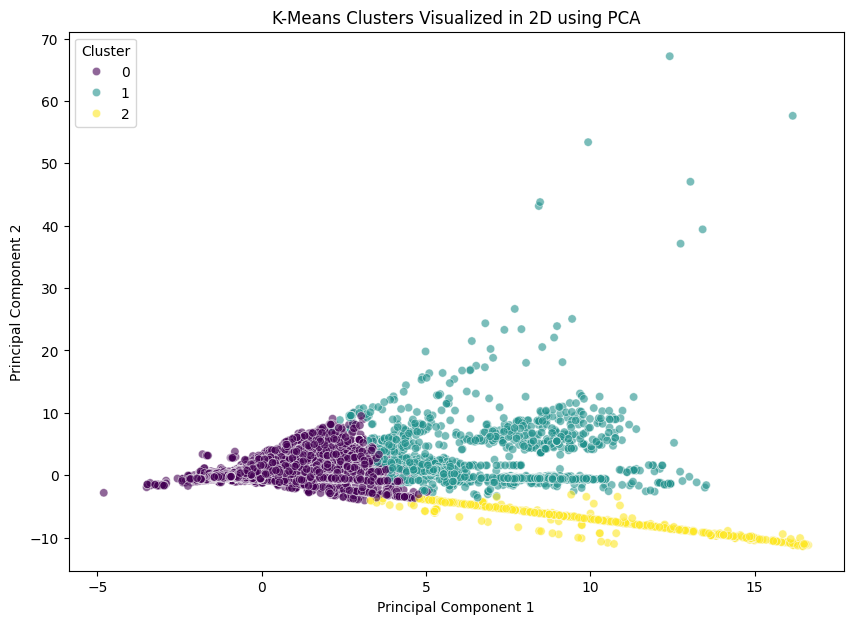

In [4]:
from sklearn.decomposition import PCA
import seaborn as sns

# Squash the 25 dimensions down to 2 dimensions (Principal Components)
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# Plot the PCA results, coloring the dots by their K-Means cluster
plt.figure(figsize=(10, 7))
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=df['KMeans_Cluster'], palette='viridis', alpha=0.6)
plt.title('K-Means Clusters Visualized in 2D using PCA')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend(title='Cluster')
plt.show()

In [8]:
# Create a table comparing the true label names to the K-Means clusters
kmeans_analysis = pd.crosstab(
    index=df['Label_Name'], 
    columns=df['KMeans_Cluster'], 
    margins=True
)

print("K-Means Cluster Distribution vs. True Labels:")
display(kmeans_analysis)

K-Means Cluster Distribution vs. True Labels:


KMeans_Cluster,0,1,2,All
Label_Name,,,,
BENIGN,39860,1409,578,41847
Bot,39,0,0,39
DDoS,2560,0,0,2560
DoS GoldenEye,182,1,23,206
DoS Hulk,2550,903,1,3454
DoS Slowhttptest,78,27,0,105
DoS slowloris,40,40,28,108
FTP-Patator,118,0,0,118
Heartbleed,1,6,0,7


## Hierarchical

In [ ]:
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score
import time

# The assignment requires testing different linkage criteria
linkage_methods = ['ward', 'complete', 'average', 'single']

# We use n_clusters=3 to match the optimal grouping we found in K-Means
best_linkage = ''
best_score = -1

print("Evaluating Hierarchical Clustering Linkage Methods...")
for linkage in linkage_methods:
    start_time = time.time()
    
    # Build the model
    hc = AgglomerativeClustering(n_clusters=3, linkage=linkage)
    
    # Fit the model and get cluster assignments
    labels = hc.fit_predict(X_scaled)
    
    # Calculate the required evaluation metrics
    sil_score = silhouette_score(X_scaled, labels)
    db_score = davies_bouldin_score(X_scaled, labels)
    
    time_taken = time.time() - start_time
    
    print(f"Linkage: {linkage:10s} | Silhouette: {sil_score:.4f} | Davies-Bouldin: {db_score:.4f} | Time: {time_taken:.1f}s")
    
    # Track the best method based on the highest Silhouette score
    if sil_score > best_score:
        best_score = sil_score
        best_linkage = linkage

print(f"\nWinner: '{best_linkage}' linkage with a Silhouette Score of {best_score:.4f}")

Evaluating Hierarchical Clustering Linkage Methods...


In [ ]:
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score
import time
import pandas as pd
import numpy as np

# 1. Take a smaller sample to save RAM (10,000 rows instead of 50,000)
# We sample 'df' and use the index to grab the exact same rows from 'X_scaled'
df_sample = df.sample(n=20000, random_state=42)
X_scaled_sample = X_scaled[df_sample.index]

# The assignment requires testing different linkage criteria
linkage_methods = ['ward', 'complete', 'average', 'single']

best_linkage = ''
best_score = -1

print("Evaluating Hierarchical Clustering Linkage Methods (on 10k sample)...")
for linkage in linkage_methods:
    start_time = time.time()
    
    # Build the model
    hc = AgglomerativeClustering(n_clusters=3, linkage=linkage)
    
    # Fit the model on the SMALLER sample
    labels = hc.fit_predict(X_scaled_sample)
    
    # Calculate metrics on the SMALLER sample
    sil_score = silhouette_score(X_scaled_sample, labels)
    db_score = davies_bouldin_score(X_scaled_sample, labels)
    
    time_taken = time.time() - start_time
    
    print(f"Linkage: {linkage:10s} | Silhouette: {sil_score:.4f} | Davies-Bouldin: {db_score:.4f} | Time: {time_taken:.1f}s")
    
    if sil_score > best_score:
        best_score = sil_score
        best_linkage = linkage

print(f"\nWinner: '{best_linkage}' linkage with a Silhouette Score of {best_score:.4f}")

Evaluating Hierarchical Clustering Linkage Methods (on 10k sample)...
Linkage: ward       | Silhouette: 0.5083 | Davies-Bouldin: 1.0370 | Time: 11.3s
Linkage: complete   | Silhouette: 0.9077 | Davies-Bouldin: 0.1237 | Time: 10.7s
Linkage: average    | Silhouette: 0.8947 | Davies-Bouldin: 0.1372 | Time: 11.1s
Linkage: single     | Silhouette: 0.9313 | Davies-Bouldin: 0.0451 | Time: 5.1s

Winner: 'single' linkage with a Silhouette Score of 0.9313


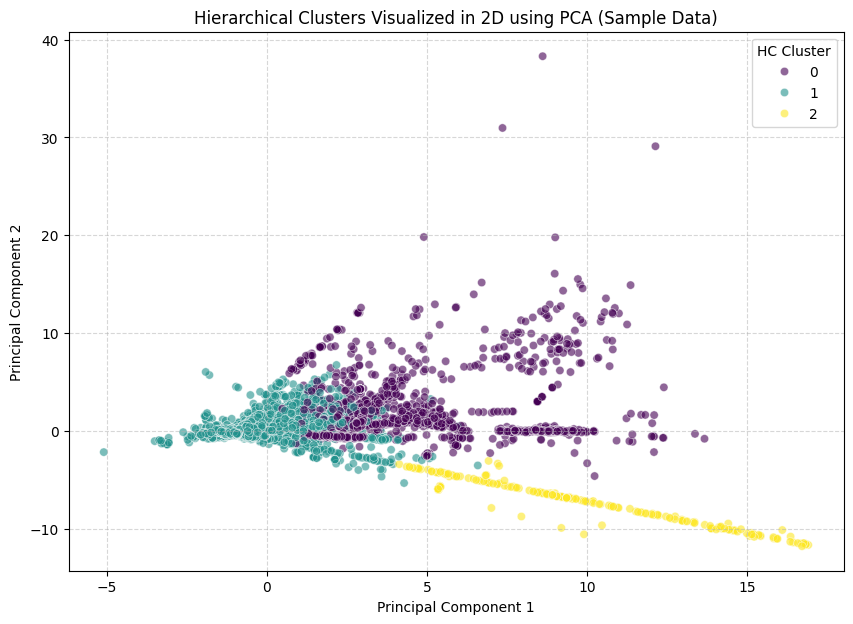

In [9]:
from sklearn.decomposition import PCA
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.cluster import AgglomerativeClustering

# 1. Fit your final Hierarchical Clustering model on the sample
# (We use 'ward' or whatever your winning linkage_method was)
hc_final = AgglomerativeClustering(n_clusters=3, linkage='ward')
df_sample['HC_Cluster'] = hc_final.fit_predict(X_scaled_sample)

# 2. Squash the dimensions down to 2 dimensions using PCA
pca = PCA(n_components=2, random_state=42)
X_pca_sample = pca.fit_transform(X_scaled_sample)

# 3. Plot the PCA results, coloring the dots by their Hierarchical Cluster
plt.figure(figsize=(10, 7))
sns.scatterplot(
    x=X_pca_sample[:, 0], 
    y=X_pca_sample[:, 1], 
    hue=df_sample['HC_Cluster'], 
    palette='viridis', 
    alpha=0.6
)
plt.title('Hierarchical Clusters Visualized in 2D using PCA (Sample Data)')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend(title='HC Cluster')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [10]:
# Map the numeric labels to their original string names using your inverse_mapping dict
df_sample['Label_Name'] = df_sample['Label'].map(inverse_mapping)

# Create a cross-tabulation table comparing string labels to the Hierarchical clusters
hc_analysis = pd.crosstab(
    index=df_sample['Label_Name'], 
    columns=df_sample['HC_Cluster'], 
    margins=True
)

print("Hierarchical Cluster Distribution vs. True Label Names (Sample Data):")
display(hc_analysis)

Hierarchical Cluster Distribution vs. True Label Names (Sample Data):


HC_Cluster,0,1,2,All
Label_Name,,,,
BENIGN,1367,15015,243,16625
Bot,0,19,0,19
DDoS,116,899,0,1015
DoS GoldenEye,3,74,4,81
DoS Hulk,1049,313,0,1362
DoS Slowhttptest,27,11,0,38
DoS slowloris,15,18,9,42
FTP-Patator,0,43,0,43
Heartbleed,4,0,0,4
